In [ ]:
# Mount the drive

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import Lasso
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error

In [ ]:


# 1. Load your stock price data (replace with your actual data source)
# Example:
#data=pd.read_csv('/content/drive/MyDrive/Data sets/Wipro_Nse.csv')
#data=pd.read_csv('/content/drive/MyDrive/Data sets/infosys.csv')
#data=pd.read_csv('/content/drive/MyDrive/Data sets/TCS new.csv')
#data=pd.read_csv('/content/drive/MyDrive/Data sets/paper 2 dataset/Dataset_Coforge.csv')
#data=pd.read_csv('/content/drive/MyDrive/Data sets/paper 2 dataset/Dataset_HCl.csv')
#data=pd.read_csv('/content/drive/MyDrive/Data sets/paper 2 dataset/Dataset_L&T_Tech.csv')
#data=pd.read_csv('/content/drive/MyDrive/Data sets/paper 2 dataset/Dataset_Mphasis.csv')
#data=pd.read_csv('/content/drive/MyDrive/Data sets/paper 2 dataset/Dataset_Persistent.csv')
#data=pd.read_csv('/content/drive/MyDrive/Data sets/paper 2 dataset/Dataset_Tech Mahindra.csv')
#data=pd.read_csv('/content/drive/MyDrive/Data sets/paper 2 dataset/Dataset_LTI Mindtree.csv')
#data=pd.read_csv('/content/drive/MyDrive/Data sets/paper 4/MRF csv.csv')
#data=pd.read_csv('/content/drive/MyDrive/Data sets/paper 4/Bajaj Auto csv.csv')
#data=pd.read_csv('/content/drive/MyDrive/Data sets/paper 4/Maruti Suzuki csv.csv')
#data=pd.read_csv('/content/drive/MyDrive/Data sets/paper 4/idbc first.csv')
#data=pd.read_csv('/content/drive/MyDrive/Data sets/paper 4/Tata Motors.csv')
data=pd.read_csv('/content/Dataset_HCl.csv')
data


,Date,series,OPEN,HIGH,LOW,PREV. CLOSE,ltp,close,vwap,52W H,52W L,VOLUME,VALUE,No of trades
0,1-Jan-19,EQ,962,965,952.85,964.35,960,959.85,959.67,"1,125.05",875.95,"3,58,734","34,42,67,067.55","13,573"
1,2-Jan-19,EQ,959,962,939.15,959.85,946.1,946.35,951.62,"1,125.05",875.95,"11,35,048","1,08,01,37,677.30","54,434"
2,3-Jan-19,EQ,950,960,945,946.35,949,948.35,951.41,"1,125.05",875.95,"14,04,612","1,33,63,62,678.70","94,610"
3,4-Jan-19,EQ,946,950.55,925,948.35,932,932.35,933.58,"1,125.05",875.95,"15,38,639","1,43,64,47,339.90","75,497"
4,7-Jan-19,EQ,939.9,950,935.9,932.35,945,941.55,943.79,"1,125.05",880.05,"11,72,376","1,10,64,76,987.25","42,886"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1250,26-Dec-23,EQ,"1,462.70","1,467.35","1,442.15","1,462.70","1,459.90","1,458.15","1,457.91","1,509.90","1,016.25","13,63,265","1,98,75,24,001.70","95,516"
1251,27-Dec-23,EQ,"1,465.45","1,476.00","1,457.55","1,458.15","1,470.00","1,472.05","1,468.79","1,509.90","1,016.25","14,02,329","2,05,97,20,063.55","93,058"
1252,28-Dec-23,EQ,"1,470.60","1,482.70","1,468.45","1,472.05","1,472.00","1,472.45","1,474.24","1,509.90","1,016.25","19,28,616","2,84,32,34,182.15","1,12,734"
1253,29-Dec-23,EQ,"1,473.95","1,481.85","1,457.55","1,472.45","1,468.00","1,466.10","1,466.79","1,509.90","1,016.25","14,81,617","2,17,32,24,444.55","1,35,316"


In [ ]:
#remove space in column names
data.columns=data.columns.str.replace(' ','')

In [ ]:
data=data[['OPEN','HIGH','LOW','PREV.CLOSE','ltp','vwap', '52WH', '52WL', 'VOLUME', 'VALUE', 'Nooftrades','close']]
data

,OPEN,HIGH,LOW,PREV.CLOSE,ltp,vwap,52WH,52WL,VOLUME,VALUE,Nooftrades,close
0,"1,145.00","1,159.70","1,136.85","1,149.30","1,150.00","1,151.35","1,425.20",637.8,"3,32,711","38,30,66,854.05","9,497","1,151.50"
1,"1,147.90","1,177.70","1,141.00","1,151.50","1,149.50","1,164.83","1,425.20",637.8,"9,31,011","1,08,44,71,138.80","23,978","1,153.30"
2,"1,153.00","1,162.95","1,127.45","1,153.30","1,128.65","1,144.06","1,425.20",637.8,"4,35,893","49,86,85,903.75","17,419","1,132.65"
3,"1,124.00","1,141.75","1,109.30","1,132.65","1,115.50","1,119.12","1,425.20",637.8,"7,23,008","80,91,35,322.85","31,343","1,122.70"
4,"1,125.90","1,148.00","1,124.95","1,122.70","1,141.00","1,139.97","1,425.20",672.05,"3,99,650","45,55,88,189.10","10,555","1,141.40"
...,...,...,...,...,...,...,...,...,...,...,...,...
1247,"6,300.00","6,342.70","6,245.00","6,290.20","6,273.00","6,289.79","6,530.00","3,564.75","2,56,576","1,61,38,08,476.80","28,163","6,276.05"
1248,"6,317.00","6,394.95","6,280.90","6,276.05","6,290.00","6,325.39","6,530.00","3,564.75","3,48,740","2,20,59,17,089.05","39,536","6,299.40"
1249,"6,325.00","6,325.00","6,240.05","6,299.40","6,285.00","6,268.87","6,530.00","3,564.75","3,20,910","2,01,17,43,435.35","26,131","6,272.35"
1250,"6,278.00","6,320.00","6,213.00","6,272.35","6,284.85","6,274.52","6,530.00","3,564.75","2,20,563","1,38,39,28,026.90","24,114","6,274.40"


In [ ]:
#Remove commas within the numerical data if exists
for col in data.columns:
  vals = data[col].values
  data[col] = [float(val.replace(',','')) if type(val) == str else val for val in vals]

/tmp/ipython-input-1137783597.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = [float(val.replace(',','')) if type(val) == str else val for val in vals]


In [ ]:
data

,OPEN,HIGH,LOW,PREV.CLOSE,ltp,vwap,52WH,52WL,VOLUME,VALUE,Nooftrades,close
0,1145.00,1159.70,1136.85,1149.30,1150.00,1151.35,1425.2,637.80,332711.0,3.830669e+08,9497.0,1151.50
1,1147.90,1177.70,1141.00,1151.50,1149.50,1164.83,1425.2,637.80,931011.0,1.084471e+09,23978.0,1153.30
2,1153.00,1162.95,1127.45,1153.30,1128.65,1144.06,1425.2,637.80,435893.0,4.986859e+08,17419.0,1132.65
3,1124.00,1141.75,1109.30,1132.65,1115.50,1119.12,1425.2,637.80,723008.0,8.091353e+08,31343.0,1122.70
4,1125.90,1148.00,1124.95,1122.70,1141.00,1139.97,1425.2,672.05,399650.0,4.555882e+08,10555.0,1141.40
...,...,...,...,...,...,...,...,...,...,...,...,...
1247,6300.00,6342.70,6245.00,6290.20,6273.00,6289.79,6530.0,3564.75,256576.0,1.613808e+09,28163.0,6276.05
1248,6317.00,6394.95,6280.90,6276.05,6290.00,6325.39,6530.0,3564.75,348740.0,2.205917e+09,39536.0,6299.40
1249,6325.00,6325.00,6240.05,6299.40,6285.00,6268.87,6530.0,3564.75,320910.0,2.011743e+09,26131.0,6272.35
1250,6278.00,6320.00,6213.00,6272.35,6284.85,6274.52,6530.0,3564.75,220563.0,1.383928e+09,24114.0,6274.40


#Compute Technical Indicators


In [ ]:
df=data

In [ ]:
  df=data
  # Simple Moving Average (SMA)
  df['SMA_5'] = df['close'].rolling(window=5).mean()
  df['SMA_10'] = df['close'].rolling(window=10).mean()
  df['SMA_20'] = df['close'].rolling(window=20).mean()

    # Exponential Moving Average (EMA)
  df['EMA_5'] = df['close'].ewm(span=5, adjust=False).mean()
  df['EMA_10'] = df['close'].ewm(span=10, adjust=False).mean()
  df['EMA_20'] = df['close'].ewm(span=20, adjust=False).mean()

    # Relative Strength Index (RSI)
  delta = df['close'].diff(1)
  gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
  loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
  rs = gain / loss
  df['RSI_14'] = 100 - (100 / (1 + rs))

    # Moving Average Convergence Divergence (MACD)
  ema_12 = df['close'].ewm(span=12, adjust=False).mean()
  ema_26 = df['close'].ewm(span=26, adjust=False).mean()
  macd = ema_12 - ema_26
  signal = macd.ewm(span=9, adjust=False).mean()
  df['MACD'] = macd
  df['Signal'] = signal

    # Stochastic Oscillator
  low_14 = df['LOW'].rolling(window=14).min()
  high_14 = df['HIGH'].rolling(window=14).max()
  df['%K'] = 100 * ((df['close'] - low_14) / (high_14 - low_14))
  df['%D'] = df['%K'].rolling(window=3).mean()

    # Bollinger Bands
  df['Middle Band'] = df['close'].rolling(window=20).mean()
  df['Upper Band'] = df['Middle Band'] + 2 * df['close'].rolling(window=20).std()
  df['Lower Band'] = df['Middle Band'] - 2 * df['close'].rolling(window=20).std()

    # Average True Range (ATR)
  high_low = df['HIGH'] - df['LOW']
  high_close = np.abs(df['HIGH'] - df['close'].shift())
  low_close = np.abs(df['LOW'] - df['close'].shift())
  tr = np.maximum(high_low, np.maximum(high_close, low_close))
  df['ATR'] = tr.rolling(window=14).mean()

    # Money Flow Index (MFI)
  typical_price = (df['HIGH'] + df['LOW'] + df['close']) / 3
  money_flow = typical_price * df['VOLUME']
  positive_flow = (money_flow.where(typical_price > typical_price.shift(), 0)).rolling(window=14).sum()
  negative_flow = (money_flow.where(typical_price < typical_price.shift(), 0)).rolling(window=14).sum()
  df['MFI_14'] = 100 * (positive_flow / (positive_flow + negative_flow))


  # Rate of Change (ROC)
df['ROC_10'] = ((df['close'] - df['close'].shift(10)) / df['close'].shift(10)) * 100
df['ROC_20'] = ((df['close'] - df['close'].shift(20)) / df['close'].shift(20)) * 100


# prompt: write a code for william %R technical indicator
'''Explanation:

1.  **Import necessary libraries:** `pandas` is already imported in your preceding code.
2.  **Define the lookback period:** A common lookback period for Williams %R is 14. You can adjust this as needed.
3.  **Calculate the highest high:** Use the `.rolling()` method on the 'HIGH' column to find the highest high over the specified `lookback_period`.
4.  **Calculate the lowest low:** Use the `.rolling()` method on the 'LOW' column to find the lowest low over the specified `lookback_period`.
5.  **Compute Williams %R:** The formula for Williams %R is:'''
# Williams %R
lookback_period = 14
highest_high = df['HIGH'].rolling(window=lookback_period).max()
lowest_low = df['LOW'].rolling(window=lookback_period).min()
df['Williams %R'] = -100 * ((highest_high - df['close']) / (highest_high - lowest_low))





/tmp/ipython-input-1379369439.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['SMA_5'] = df['close'].rolling(window=5).mean()


In [ ]:
df

,OPEN,HIGH,LOW,PREV.CLOSE,ltp,vwap,52WH,52WL,VOLUME,VALUE,Nooftrades,close
0,1145.00,1159.70,1136.85,1149.30,1150.00,1151.35,1425.2,637.80,332711.0,3.830669e+08,9497.0,1151.50
1,1147.90,1177.70,1141.00,1151.50,1149.50,1164.83,1425.2,637.80,931011.0,1.084471e+09,23978.0,1153.30
2,1153.00,1162.95,1127.45,1153.30,1128.65,1144.06,1425.2,637.80,435893.0,4.986859e+08,17419.0,1132.65
3,1124.00,1141.75,1109.30,1132.65,1115.50,1119.12,1425.2,637.80,723008.0,8.091353e+08,31343.0,1122.70
4,1125.90,1148.00,1124.95,1122.70,1141.00,1139.97,1425.2,672.05,399650.0,4.555882e+08,10555.0,1141.40
...,...,...,...,...,...,...,...,...,...,...,...,...
1247,6300.00,6342.70,6245.00,6290.20,6273.00,6289.79,6530.0,3564.75,256576.0,1.613808e+09,28163.0,6276.05
1248,6317.00,6394.95,6280.90,6276.05,6290.00,6325.39,6530.0,3564.75,348740.0,2.205917e+09,39536.0,6299.40
1249,6325.00,6325.00,6240.05,6299.40,6285.00,6268.87,6530.0,3564.75,320910.0,2.011743e+09,26131.0,6272.35
1250,6278.00,6320.00,6213.00,6272.35,6284.85,6274.52,6530.0,3564.75,220563.0,1.383928e+09,24114.0,6274.40


In [ ]:
df.columns

Index(['OPEN', 'HIGH', 'LOW', 'PREV.CLOSE', 'ltp', 'vwap', '52WH', '52WL',
       'VOLUME', 'VALUE', 'Nooftrades', 'close'],
      dtype='object')

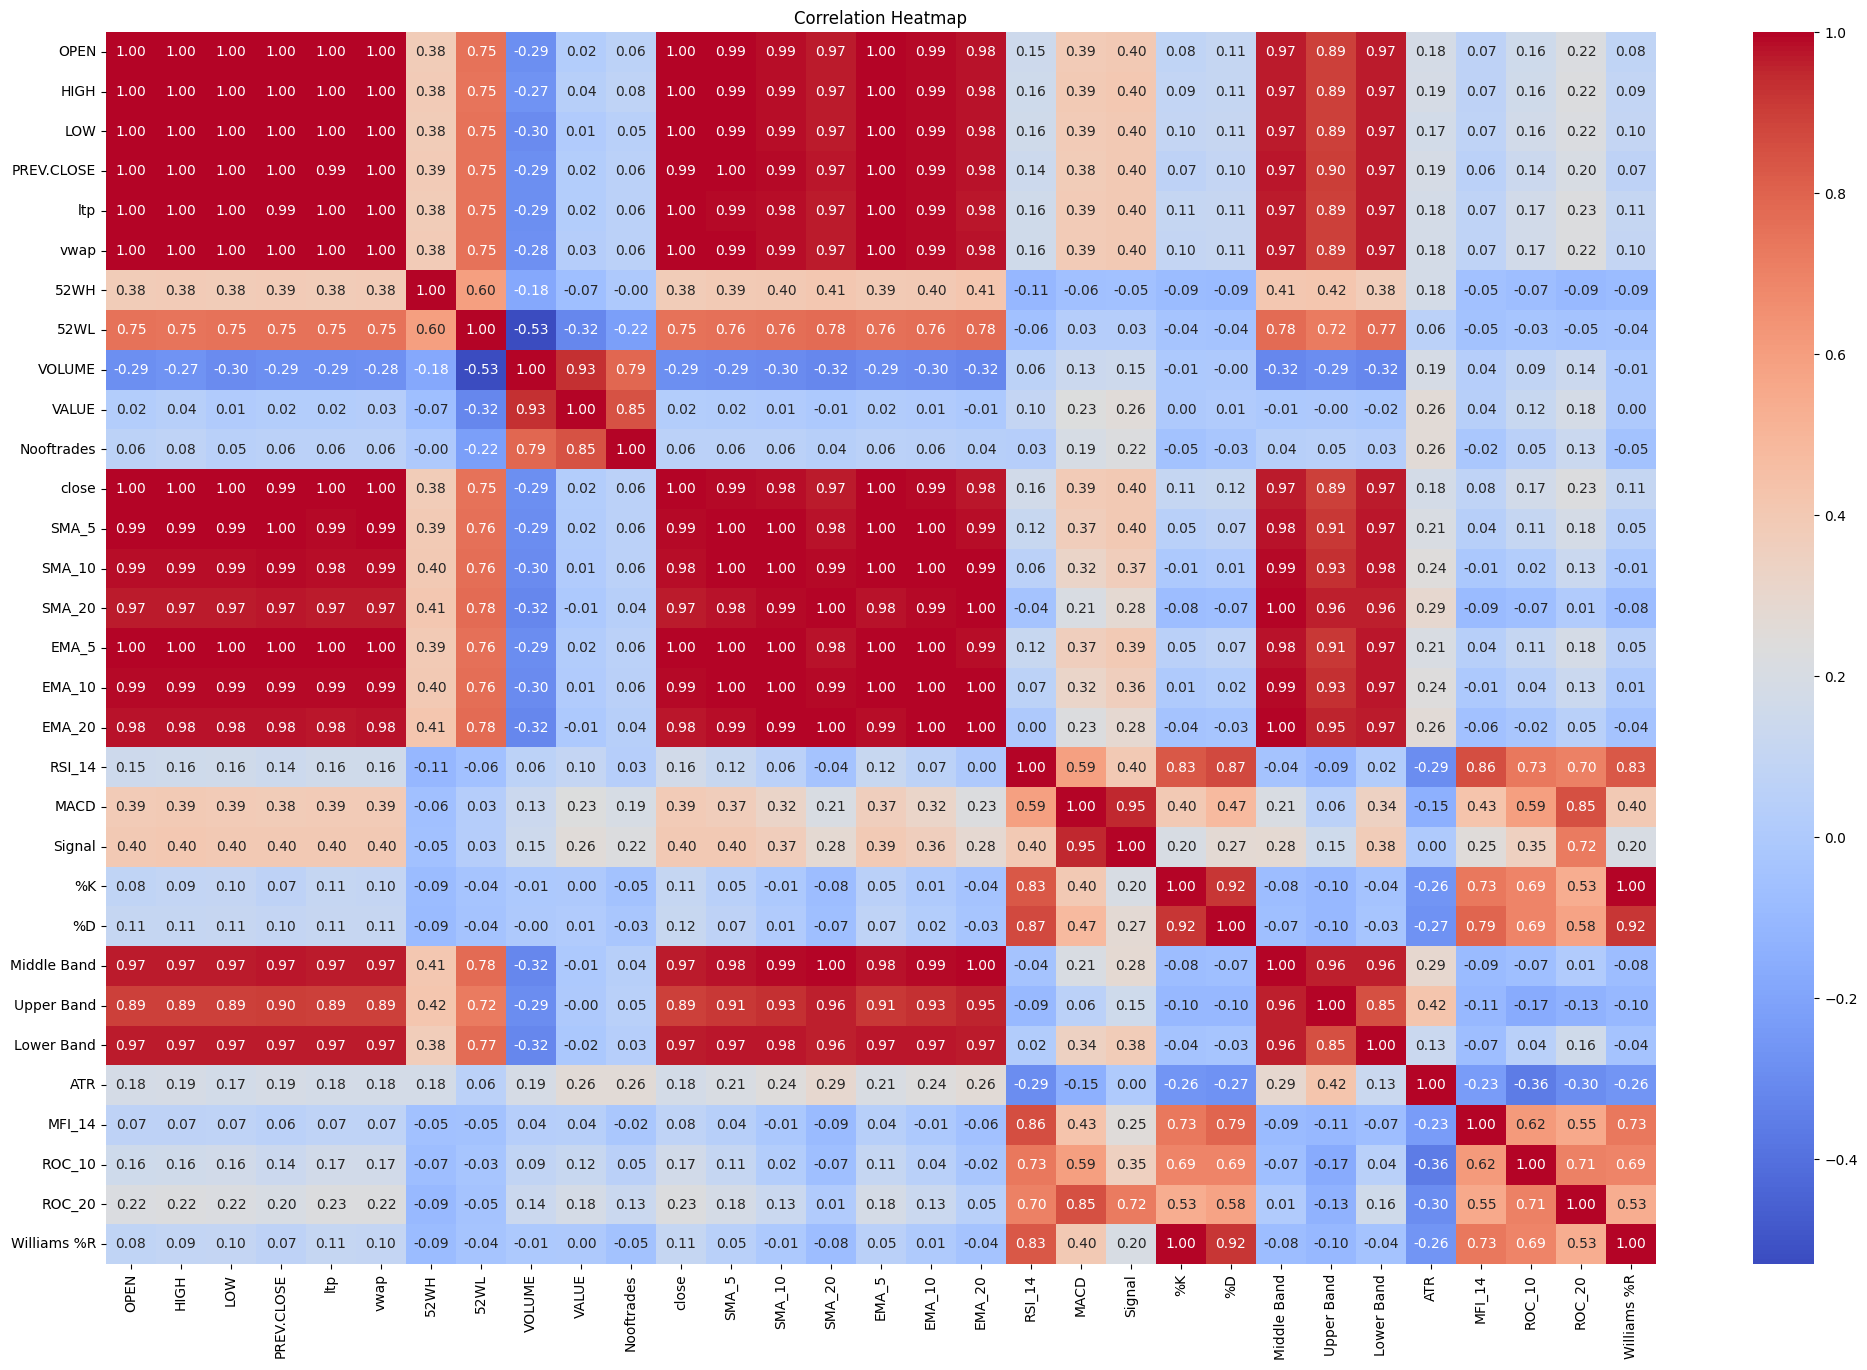

In [ ]:
# prompt: draw the correlation heatmap

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the correlation matrix
correlation_matrix = df.corr()

# Create the heatmap
plt.figure(figsize=(25, 16))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()


In [ ]:
# prompt: compute no of NAN values

# Count the number of NaN values in each column of X
nan_counts = df.isnull().sum()

# Print the counts
print(nan_counts)

# Total number of NaN values
total_nan = nan_counts.sum()
print(f"\nTotal number of NaN values in X: {total_nan}")


OPEN          0
HIGH          0
LOW           0
PREV.CLOSE    0
ltp           0
vwap          0
52WH          0
52WL          0
VOLUME        0
VALUE         0
Nooftrades    0
close         0
dtype: int64

Total number of NaN values in X: 0


In [ ]:
# Drop rows with NaN values introduced by technical indicators
df.dropna(inplace=True)

# Define features (X) and target (y)
X = df.drop('close', axis=1)
y = df['close']

# Scale the data
scaler_X = MinMaxScaler(feature_range=(0, 1))
scaler_y = MinMaxScaler(feature_range=(0, 1))

X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y.values.reshape(-1, 1))

/tmp/ipython-input-2885466450.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.dropna(inplace=True)


In [ ]:
# prompt: apply autoencoder

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras import regularizers

# Define the input layer
input_layer = Input(shape=(X_scaled.shape[1],))

# Encoder
encoded = Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(input_layer)
encoded = Dense(32, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(encoded)
encoder_output = Dense(16, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(encoded) # Bottleneck layer

# Decoder
decoded = Dense(32, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(encoder_output)
decoded = Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(decoded)
decoded_output = Dense(X_scaled.shape[1], activation='sigmoid')(decoded) # Output layer has the same number of neurons as input

# Build the Autoencoder model
autoencoder = Model(inputs=input_layer, outputs=decoded_output)

# Compile the Autoencoder
autoencoder.compile(optimizer='adam', loss='mse')

# Train the Autoencoder
# We train the autoencoder on the scaled features (X_scaled)
history_autoencoder = autoencoder.fit(X_scaled, X_scaled,
                                      epochs=200, # You can adjust the number of epochs
                                      batch_size=64, # You can adjust the batch size
                                      shuffle=True,
                                      validation_split=0.2, # Use a validation split
                                      verbose=1) # Set to 0 for less output

# Extract the encoder part of the autoencoder
encoder = Model(inputs=input_layer, outputs=encoder_output)

# Use the encoder to transform the original data into the lower-dimensional representation
X_encoded = encoder.predict(X_scaled)

print("Original data shape:", X_scaled.shape)
print("Encoded data shape:", X_encoded.shape)

# You can now use X_encoded for further tasks like clustering, visualization, or as input to another model
# For instance, you could use X_encoded as input to the LSTM model you might build later.

Epoch 1/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 447ms/step - loss: 0.1456 - val_loss: 0.1047
Epoch 2/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1250 - val_loss: 0.0820
Epoch 3/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0981 - val_loss: 0.0704
Epoch 4/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0770 - val_loss: 0.0492
Epoch 5/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0595 - val_loss: 0.0346
Epoch 6/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0346 - val_loss: 0.0242
Epoch 7/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0188 - val_loss: 0.0230
Epoch 8/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0151 - val_loss: 0.0210
Epoch 9/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0139 - val_loss: 0.0185
Epoch 10/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0130 - val_loss: 0.0184
Epoch 11/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0126 - val_loss: 0.0172
Epoch 12/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 

In [ ]:
X_encoded

array([[0.28671718, 0.42183402, 0.51148224, ..., 0.36639366, 0.        ,
        0.00551286],
       [0.28523213, 0.41837043, 0.5147443 , ..., 0.3677616 , 0.        ,
        0.00782341],
       [0.2864407 , 0.42123872, 0.5122533 , ..., 0.3663338 , 0.        ,
        0.00538936],
       ...,
       [0.19995819, 0.13555612, 0.14496356, ..., 0.98161614, 0.        ,
        1.1433525 ],
       [0.20109566, 0.13831134, 0.14331806, ..., 0.9796339 , 0.        ,
        1.1398735 ],
       [0.20284227, 0.14259332, 0.14115945, ..., 0.97614735, 0.        ,
        1.1337304 ]], dtype=float32)

In [ ]:
X_encoded.shape


(1252, 16)

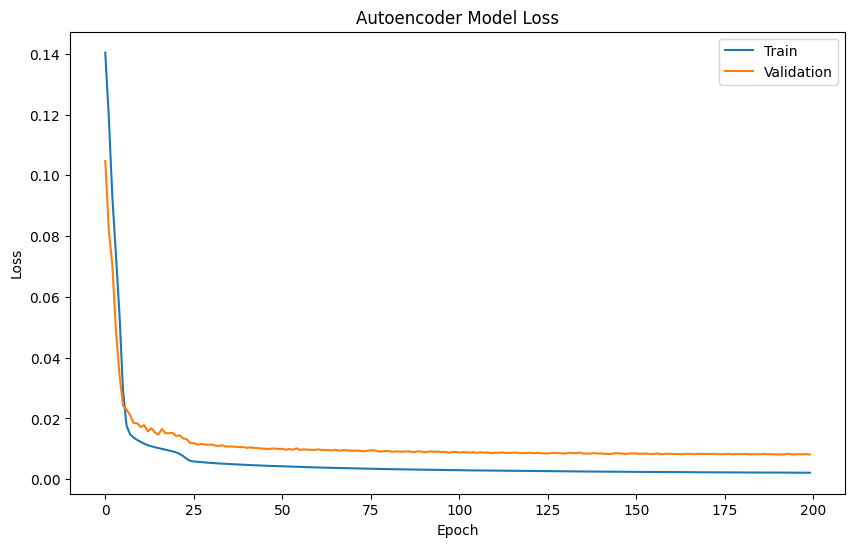

In [ ]:
# prompt: plot enoder training loss, validation loss and test loss

# Plot training & validation loss values
plt.figure(figsize=(10, 6))
plt.plot(history_autoencoder.history['loss'])
plt.plot(history_autoencoder.history['val_loss'])
# Assuming you have a test set and evaluated the loss on it
# If you trained on train and validated on validation, you might need to calculate test loss separately
# For example:
# test_loss = autoencoder.evaluate(X_test_scaled, X_test_scaled, verbose=0)
# plt.axhline(y=test_loss, color='r', linestyle='--', label='Test Loss') # Add a line for test loss if calculated


plt.title('Autoencoder Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation', 'Test'], loc='upper right')
plt.show()

In [ ]:
# Function to create sequences for LSTM
def create_sequences(X, y, time_steps=1):
    Xs, ys = [], []
    for i in range(len(X) - time_steps):
        v = X[i:(i + time_steps)]
        Xs.append(v)
        ys.append(y[i + time_steps])
    return np.array(Xs), np.array(ys)

# Define the number of time steps (look back period)
TIME_STEPS = 30

# Create sequences for the encoded data
X_seq, y_seq = create_sequences(X_encoded, y_scaled, TIME_STEPS)

# Create sequences for the scaled data
#X_seq, y_seq = create_sequences(X_scaled, y_scaled, TIME_STEPS)

# Split data into training, validation, and test sets
# We'll use a chronological split (e.g., 70% train, 15% validation, 15% test)
train_size = int(len(X_seq) * 0.7)
val_size = int(len(X_seq) * 0.15)
test_size = len(X_seq) - train_size - val_size

X_train, y_train = X_seq[0:train_size], y_seq[0:train_size]
X_val, y_val = X_seq[train_size:train_size+val_size], y_seq[train_size:train_size+val_size]
X_test, y_test = X_seq[train_size+val_size:], y_seq[train_size+val_size:]

print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_val shape: {X_val.shape}")
print(f"y_val shape: {y_val.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (855, 30, 16)
y_train shape: (855, 1)
X_val shape: (183, 30, 16)
y_val shape: (183, 1)
X_test shape: (184, 30, 16)
y_test shape: (184, 1)


#LSTM


Starting Single Step Hyperparameter Tuning...

Training with params: units=70, dropout=0.1, lr=0.001, epochs=100, batch_size=32, activation=relu


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Streaming output truncated to the last 5000 lines.
Epoch 41/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0017 - val_loss: 0.0012
Epoch 42/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0016 - val_loss: 0.0021
Epoch 43/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0016 - val_loss: 0.0012
Epoch 44/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0016 - val_loss: 0.0011
Epoch 45/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0017 - val_loss: 0.0020
Epoch 46/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0016 - val_loss: 0.0011
Epoch 47/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0016 - val_loss: 0.0022
Epoch 48/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0015 - val_loss: 0.0012
Epoch 49/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0016 - val_loss: 0.0018
Epoch 50/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0017 - val_loss: 0.0013
Epoch 51/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0015 - val_loss:

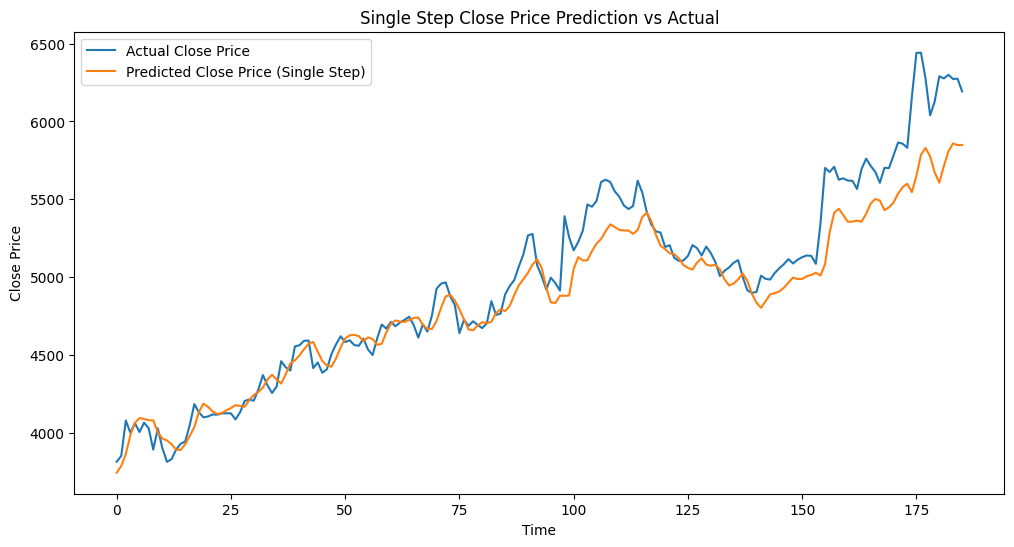

'\n# --- Multistep Prediction ---\n\n# Function to create sequences for LSTM multistep\ndef create_sequences_multistep(X, y, time_steps=1, future_steps=1):\n    Xs, Ys = [], []\n    for i in range(len(X) - time_steps - future_steps + 1):\n        v = X[i:(i + time_steps)]\n        Xs.append(v)\n        Ys.append(y[i + time_steps:i + time_steps + future_steps])\n    return np.array(Xs), np.array(Ys)\n\n# Define the number of future steps to predict\nFUTURE_STEPS = 5 # Example: predict 5 steps into the future\n\n# Create sequences for multistep prediction\n# Note: Multistep prediction requires a different target shape (samples, future_steps, features)\n# Here, we\'re simplifying by predicting a fixed number of future \'close\' values.\n# A common approach is seq2seq, but we\'ll use a simpler Dense layer outputting `future_steps` values.\nX_seq_multi, y_seq_multi = create_sequences_multistep(X_scaled, y_scaled, TIME_STEPS, FUTURE_STEPS)\n\n# Split data for multistep prediction\ntrain_size

In [ ]:
# prompt: now the dataset df is ready. we need to predict the closing price. split the dataset into training, validation and test set and then implement the LSTM to perform single step and multistep closing price prediction. perform hyperparameter tuning of LSTM using grid search without using " tensorflow.keras.wrappers.scikit_learn import KerasRegressor"


# --- Single Step Prediction ---

# Define the LSTM model creation function for single step
def build_lstm_single_step(units=50, dropout=0.2, learning_rate=0.001, activation='tanh'):
    model = Sequential()
    model.add(LSTM(units=units, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2]), activation=activation))
    model.add(Dropout(dropout))
    model.add(LSTM(units=units, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2]), activation=activation))
    model.add(Dropout(dropout))
    model.add(LSTM(units=units, return_sequences=False, input_shape=(X_train.shape[1], X_train.shape[2]), activation=activation))
    model.add(Dropout(dropout))
    model.add(Dense(units=1))
    optimizer = Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss='mse')
    return model

# Hyperparameter grid for single step
param_grid_single_step = {
    'units': [70, 100],   #50,
    'dropout': [0.1, 0.2],
    'learning_rate': [0.001, 0.0005],
    'epochs': [100], # Reduced epochs for faster grid search
    'batch_size': [32, 64],
    'activation': [ 'relu','tanh'] #'relu',
}

best_mse_single_step = float('inf')
best_params_single_step = {}
best_model_single_step = None

print("\nStarting Single Step Hyperparameter Tuning...")

# Manual Grid Search for Single Step
for units in param_grid_single_step['units']:
    for dropout in param_grid_single_step['dropout']:
        for learning_rate in param_grid_single_step['learning_rate']:
            for epochs in param_grid_single_step['epochs']:
                for batch_size in param_grid_single_step['batch_size']:
                    for activation in param_grid_single_step['activation']:
                        print(f"\nTraining with params: units={units}, dropout={dropout}, lr={learning_rate}, epochs={epochs}, batch_size={batch_size}, activation={activation}")

                        # Build and train the model
                        model = build_lstm_single_step(units=units, dropout=dropout, learning_rate=learning_rate, activation=activation)

                        history = model.fit(X_train, y_train,
                                            epochs=epochs,
                                            batch_size=batch_size,
                                            validation_data=(X_val, y_val),
                                            verbose=1) # Set to 1 to see progress

                        # Evaluate on validation set
                        val_loss = model.evaluate(X_val, y_val, verbose=0)
                        print(f"Validation Loss (MSE): {val_loss}")

                        # Check if this is the best model so far
                        if val_loss < best_mse_single_step:
                            best_mse_single_step = val_loss
                            best_params_single_step = {
                                'units': units,
                                'dropout': dropout,
                                'learning_rate': learning_rate,
                                'epochs': epochs,
                                'batch_size': batch_size,
                                'activation': activation
                            }
                            best_model_single_step = model

print("\nSingle Step Tuning Complete.")
print("Best Single Step Parameters:", best_params_single_step)
print("Best Single Step Validation MSE:", best_mse_single_step)

# Evaluate the best single step model on the test set
y_pred_scaled_single_step = best_model_single_step.predict(X_test)
y_test_single_step = scaler_y.inverse_transform(y_test)
y_pred_single_step = scaler_y.inverse_transform(y_pred_scaled_single_step)

mse_single_step = mean_squared_error(y_test_single_step, y_pred_single_step)
print(f'\nSingle Step Test MSE: {mse_single_step}')

# Plotting for single step prediction (optional)
plt.figure(figsize=(12, 6))
plt.plot(y_test_single_step, label='Actual Close Price')
plt.plot(y_pred_single_step, label='Predicted Close Price (Single Step)')
plt.title('Single Step Close Price Prediction vs Actual')
plt.xlabel('Time')
plt.ylabel('Close Price')
plt.legend()
plt.show()

'''
# --- Multistep Prediction ---

# Function to create sequences for LSTM multistep
def create_sequences_multistep(X, y, time_steps=1, future_steps=1):
    Xs, Ys = [], []
    for i in range(len(X) - time_steps - future_steps + 1):
        v = X[i:(i + time_steps)]
        Xs.append(v)
        Ys.append(y[i + time_steps:i + time_steps + future_steps])
    return np.array(Xs), np.array(Ys)

# Define the number of future steps to predict
FUTURE_STEPS = 5 # Example: predict 5 steps into the future

# Create sequences for multistep prediction
# Note: Multistep prediction requires a different target shape (samples, future_steps, features)
# Here, we're simplifying by predicting a fixed number of future 'close' values.
# A common approach is seq2seq, but we'll use a simpler Dense layer outputting `future_steps` values.
X_seq_multi, y_seq_multi = create_sequences_multistep(X_scaled, y_scaled, TIME_STEPS, FUTURE_STEPS)

# Split data for multistep prediction
train_size_multi = int(len(X_seq_multi) * 0.7)
val_size_multi = int(len(X_seq_multi) * 0.15)
test_size_multi = len(X_seq_multi) - train_size_multi - val_size_multi

X_train_multi, y_train_multi = X_seq_multi[0:train_size_multi], y_seq_multi[0:train_size_multi]
X_val_multi, y_val_multi = X_seq_multi[train_size_multi:train_size_multi+val_size_multi], y_seq_multi[train_size_multi:train_size_multi+val_size_multi]
X_test_multi, y_test_multi = X_seq_multi[train_size_multi+val_size_multi:], y_seq_multi[train_size_multi+val_size_multi:]

print(f"\nX_train_multi shape: {X_train_multi.shape}")
print(f"y_train_multi shape: {y_train_multi.shape}") # Should be (samples, future_steps, 1)
print(f"X_val_multi shape: {X_val_multi.shape}")
print(f"y_val_multi shape: {y_val_multi.shape}")
print(f"X_test_multi shape: {X_test_multi.shape}")
print(f"y_test_multi shape: {y_test_multi.shape}")

# Reshape y_train_multi, y_val_multi, y_test_multi for the simple Dense output model
# Flatten the last two dimensions: (samples, future_steps * features)
y_train_multi_flat = y_train_multi.reshape(y_train_multi.shape[0], -1)
y_val_multi_flat = y_val_multi.reshape(y_val_multi.shape[0], -1)
y_test_multi_flat = y_test_multi.reshape(y_test_multi.shape[0], -1)


# Define the LSTM model creation function for multistep
def build_lstm_multistep(units=50, dropout=0.2, learning_rate=0.001, activation='tanh', future_steps=1):
    model = Sequential()
    # Keep return_sequences=True for deeper LSTM layers if needed, but False is common before Dense output
    model.add(LSTM(units=units, return_sequences=False, input_shape=(X_train_multi.shape[1], X_train_multi.shape[2]), activation=activation))
    model.add(Dropout(dropout))
    model.add(Dense(units=future_steps)) # Output layer predicts future_steps values
    optimizer = Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss='mse')
    return model

# Hyperparameter grid for multistep (can be similar to single step)
param_grid_multistep = {
    'units': [50, 70, 100],
    'dropout': [0.1, 0.2, 0.3],
    'learning_rate': [0.001, 0.0005],
    'epochs': [50, 100], # Reduced epochs for faster grid search
    'batch_size': [32, 64],
    'activation': ['relu', 'tanh']
}

best_mse_multistep = float('inf')
best_params_multistep = {}
best_model_multistep = None

print("\nStarting Multistep Hyperparameter Tuning...")

# Manual Grid Search for Multistep
for units in param_grid_multistep['units']:
    for dropout in param_grid_multistep['dropout']:
        for learning_rate in param_grid_multistep['learning_rate']:
            for epochs in param_grid_multistep['epochs']:
                for batch_size in param_grid_multistep['batch_size']:
                     for activation in param_grid_multistep['activation']:
                        print(f"\nTraining with params: units={units}, dropout={dropout}, lr={learning_rate}, epochs={epochs}, batch_size={batch_size}, activation={activation}")

                        # Build and train the model
                        model = build_lstm_multistep(units=units, dropout=dropout, learning_rate=learning_rate, activation=activation, future_steps=FUTURE_STEPS)

                        history = model.fit(X_train_multi, y_train_multi_flat,
                                            epochs=epochs,
                                            batch_size=batch_size,
                                            validation_data=(X_val_multi, y_val_multi_flat),
                                            verbose=0) # Set to 1 to see progress

                        # Evaluate on validation set
                        val_loss = model.evaluate(X_val_multi, y_val_multi_flat, verbose=0)
                        print(f"Validation Loss (MSE): {val_loss}")

                        # Check if this is the best model so far
                        if val_loss < best_mse_multistep:
                            best_mse_multistep = val_loss
                            best_params_multistep = {
                                'units': units,
                                'dropout': dropout,
                                'learning_rate': learning_rate,
                                'epochs': epochs,
                                'batch_size': batch_size,
                                'activation': activation
                            }
                            best_model_multistep = model

print("\nMultistep Tuning Complete.")
print("Best Multistep Parameters:", best_params_multistep)
print("Best Multistep Validation MSE:", best_mse_multistep)

# Evaluate the best multistep model on the test set
y_pred_scaled_multistep = best_model_multistep.predict(X_test_multi)

# Inverse transform the predictions and actual values for evaluation
# Reshape the predictions back to (samples, future_steps, 1) for inverse scaling
y_pred_scaled_multistep_reshaped = y_pred_scaled_multistep.reshape(-1, FUTURE_STEPS, 1)
y_test_multi_reshaped = y_test_multi.reshape(-1, FUTURE_STEPS, 1) # Ensure y_test_multi is also reshaped

y_test_multistep = scaler_y.inverse_transform(y_test_multi_reshaped.reshape(-1, 1)).reshape(-1, FUTURE_STEPS)
y_pred_multistep = scaler_y.inverse_transform(y_pred_scaled_multistep_reshaped.reshape(-1, 1)).reshape(-1, FUTURE_STEPS)


# Evaluate MSE for each future step
mse_multistep_steps = [mean_squared_error(y_test_multistep[:, i], y_pred_multistep[:, i]) for i in range(FUTURE_STEPS)]

print(f'\nMultistep Test MSE for each step ({FUTURE_STEPS} steps):')
for i, mse in enumerate(mse_multistep_steps):
    print(f'  Step {i+1}: {mse:.4f}')

# Overall MSE for multistep prediction (average over steps)
overall_mse_multistep = np.mean(mse_multistep_steps)
print(f'Overall Multistep Test MSE: {overall_mse_multistep:.4f}')


# Plotting for multistep prediction (optional - showing predictions for the first sequence)
plt.figure(figsize=(12, 6))
# Plot the actual sequence
plt.plot(range(TIME_STEPS, TIME_STEPS + FUTURE_STEPS), y_test_multistep[0], label='Actual Future Close Price')
# Plot the predicted sequence
plt.plot(range(TIME_STEPS, TIME_STEPS + FUTURE_STEPS), y_pred_multistep[0], label='Predicted Future Close Price (Multistep)')
plt.title('Multistep Close Price Prediction (First Test Sequence)')
plt.xlabel('Time Steps from Sequence Start')
plt.ylabel('Close Price')
plt.legend()
plt.show()
'''


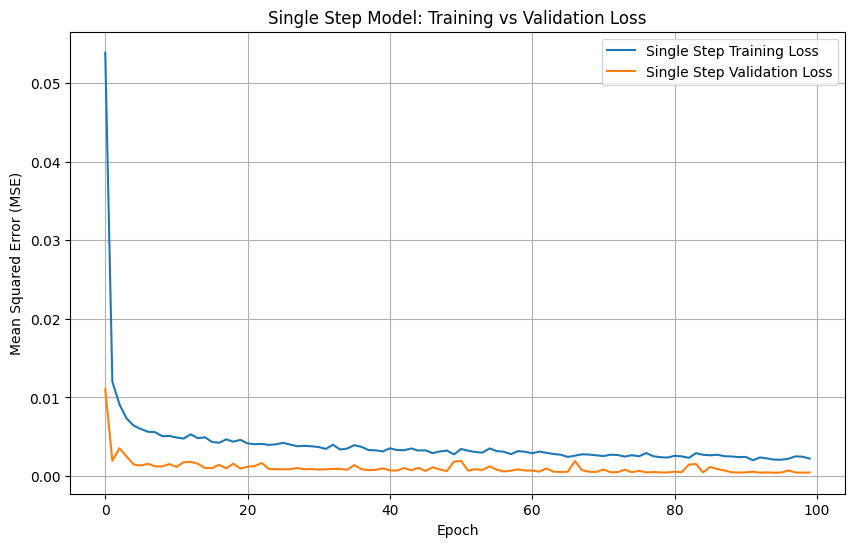

In [ ]:
# prompt: plot validation loss and training loss of single step prediction

# Get the training history for the best single-step model
# Assuming 'history' from the last training run is available.
# If not, you would need to re-train the best_model_single_step and capture its history.
# Let's assume `history_single_step` was saved during the best model training.
# If the history object isn't explicitly saved for the best model,
# you would need to re-run the fit call for the best model and capture its output.

# Placeholder for getting history if it wasn't saved during tuning:
# best_model_single_step = build_lstm_single_step(**best_params_single_step)
# history_single_step = best_model_single_step.fit(
#     X_train, y_train,
#     epochs=best_params_single_step['epochs'],
#     batch_size=best_params_single_step['batch_size'],
#     validation_data=(X_val, y_val),
#     verbose=0
# )

# Assuming the `history` object captured during the *best* single-step model training run is available
history_single_step = history # This assumes the last history object captured is for the best model.
                             # In a robust implementation, you would save the history associated
                             # with the best_model_single_step during the grid search.


# Plotting training and validation loss for single step
plt.figure(figsize=(10, 6))
plt.plot(history_single_step.history['loss'], label='Single Step Training Loss')
plt.plot(history_single_step.history['val_loss'], label='Single Step Validation Loss')
plt.title('Single Step Model: Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error (MSE)')
plt.legend()
plt.grid(True)
plt.show()



In [ ]:
# prompt: make a dataframe of actual price and predicted price in single step prediction

# Create a DataFrame for single step actual vs predicted prices
df_single_step_results = pd.DataFrame({
    'Actual Close Price (Single Step)': y_test_single_step.flatten(),
    'Predicted Close Price (Single Step)': y_pred_single_step.flatten()
})

print("\nSingle Step Prediction Results:")
print(df_single_step_results.head()) # Display the first few rows




Single Step Prediction Results:
   Actual Close Price (Single Step)  Predicted Close Price (Single Step)
0                           1098.15                          1074.770264
1                           1111.20                          1086.978271
2                           1091.85                          1092.332153
3                           1103.10                          1096.128784
4                           1087.00                          1089.491821


In [ ]:
df_single_step_results

,Actual Close Price (Single Step),Predicted Close Price (Single Step)
0,1098.15,1074.770264
1,1111.20,1086.978271
2,1091.85,1092.332153
3,1103.10,1096.128784
4,1087.00,1089.491821
...,...,...
180,1458.15,1413.132446
181,1472.05,1426.240479
182,1472.45,1430.643311
183,1466.10,1436.230469


In [ ]:
# prompt: plot df_single_step_results using interactive plot

!pip install plotly

import plotly.express as px

fig = px.line(df_single_step_results, y=['Actual Close Price (Single Step)', 'Predicted Close Price (Single Step)'],
              title='Single Step Close Price Prediction vs Actual (Interactive)',width=1000, height=400)
fig.update_layout(xaxis_title='Time Index', yaxis_title='Close Price')
fig.show()

In [ ]:
# prompt: compute MAPE, R-Square , MSE, RMSE, MAE of df_single_step_results

from sklearn.metrics import r2_score

# Compute evaluation metrics for single step prediction

# Mean Absolute Percentage Error (MAPE)
def mean_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    # Avoid division by zero, replace 0 actual values with a small epsilon
    epsilon = np.finfo(np.float64).eps
    return np.mean(np.abs((y_true - y_pred) / np.maximum(epsilon, y_true))) * 100

mape_single_step = mean_absolute_percentage_error(df_single_step_results['Actual Close Price (Single Step)'],
                                                  df_single_step_results['Predicted Close Price (Single Step)'])

# R-squared (R2)
r2_single_step = r2_score(df_single_step_results['Actual Close Price (Single Step)'],
                          df_single_step_results['Predicted Close Price (Single Step)'])

# Mean Squared Error (MSE)
# Already computed as `mse_single_step`

# Root Mean Squared Error (RMSE)
rmse_single_step = np.sqrt(mse_single_step)

# Mean Absolute Error (MAE)
mae_single_step = np.mean(np.abs(df_single_step_results['Actual Close Price (Single Step)'] -
                                 df_single_step_results['Predicted Close Price (Single Step)']))

print("\nSingle Step Evaluation Metrics:")
print(f'MAPE: {mape_single_step:.2f}%')
print(f'R-squared: {r2_single_step:.4f}')
print(f'MSE: {mse_single_step:.4f}')
print(f'RMSE: {rmse_single_step:.4f}')
print(f'MAE: {mae_single_step:.4f}')


Single Step Evaluation Metrics:
MAPE: 1.53%
R-squared: 0.9446
MSE: 644.0263
RMSE: 25.3777
MAE: 19.0837


#Prediction using GRU


Starting Single Step GRU Hyperparameter Tuning...

Training GRU with params: units=50, dropout=0.1, lr=0.001, epochs=100, batch_size=32, activation=relu


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Streaming output truncated to the last 5000 lines.
Epoch 41/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0011 - val_loss: 6.5478e-04
Epoch 42/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0014 - val_loss: 7.5850e-04
Epoch 43/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0011 - val_loss: 7.4876e-04
Epoch 44/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 0.0011 - val_loss: 6.5027e-04
Epoch 45/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.0012 - val_loss: 7.3308e-04
Epoch 46/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 0.0010 - val_loss: 6.5685e-04
Epoch 47/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 0.0010 - val_loss: 7.2191e-04
Epoch 48/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 9.6706e-04 - val_loss: 7.8213e-04
Epoch 49/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.0011 - val_loss: 6.1746e-04
Epoch 50/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.0011 - val_loss: 6.1440e-04
Epoch 51/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - lo

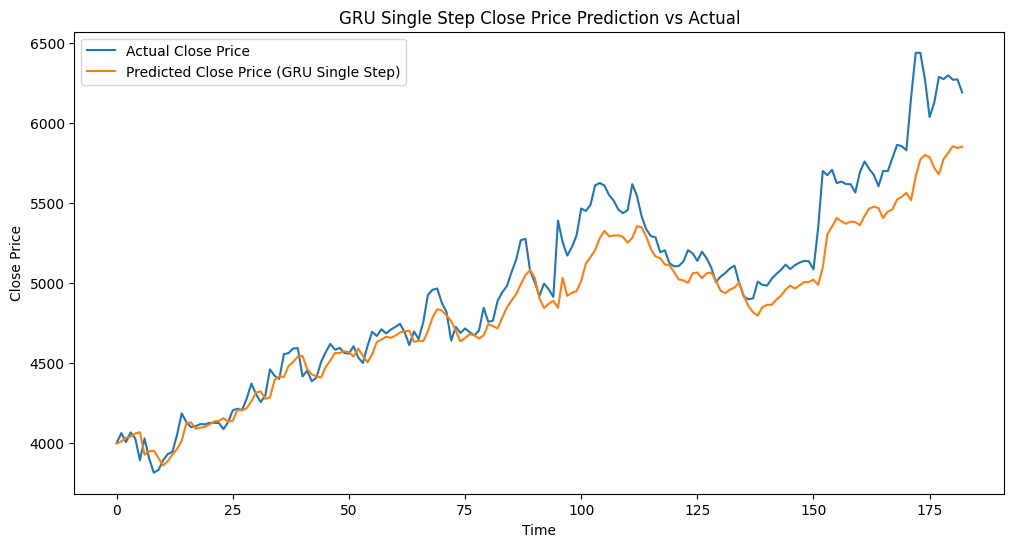


Single Step GRU Prediction Results:
   Actual Close Price (GRU Single Step)  \
0                               4000.10   
1                               4061.30   
2                               4004.85   
3                               4065.20   
4                               4028.70   

   Predicted Close Price (GRU Single Step)  
0                              3996.196045  
1                              4008.644287  
2                              4031.898438  
3                              4039.130371  
4                              4059.183594  


In [ ]:
# prompt: Also Create GRU to perform same single step prediction

from tensorflow.keras.layers import GRU

# --- Single Step Prediction using GRU ---

# Define the GRU model creation function for single step
def build_gru_single_step(units=50, dropout=0.2, learning_rate=0.001, activation='tanh'):
    model = Sequential()
    model.add(GRU(units=units, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2]), activation=activation))
    model.add(Dropout(dropout))

    model.add(GRU(units=units, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2]), activation=activation))
    model.add(Dropout(dropout))
    model.add(LSTM(units=units, return_sequences=False, input_shape=(X_train.shape[1], X_train.shape[2]), activation=activation))
    model.add(Dropout(dropout))

    model.add(Dense(units=1))
    optimizer = Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss='mse')
    return model

# Hyperparameter grid for single step GRU (can be similar to LSTM)
param_grid_gru_single_step = {
    'units': [50, 100],
    'dropout': [0.1, 0.2, 0.3],
    'learning_rate': [0.001, 0.0005],
    'epochs': [100], # Reduced epochs for faster grid search
    'batch_size': [32, 64],
    'activation': ['relu', 'tanh']
}

best_mse_gru_single_step = float('inf')
best_params_gru_single_step = {}
best_model_gru_single_step = None
history_gru_single_step = None # To store history of the best model

print("\nStarting Single Step GRU Hyperparameter Tuning...")

# Manual Grid Search for Single Step GRU
for units in param_grid_gru_single_step['units']:
    for dropout in param_grid_gru_single_step['dropout']:
        for learning_rate in param_grid_gru_single_step['learning_rate']:
            for epochs in param_grid_gru_single_step['epochs']:
                for batch_size in param_grid_gru_single_step['batch_size']:
                    for activation in param_grid_gru_single_step['activation']:
                        print(f"\nTraining GRU with params: units={units}, dropout={dropout}, lr={learning_rate}, epochs={epochs}, batch_size={batch_size}, activation={activation}")

                        # Build and train the model
                        model = build_gru_single_step(units=units, dropout=dropout, learning_rate=learning_rate, activation=activation)

                        history = model.fit(X_train, y_train,
                                            epochs=epochs,
                                            batch_size=batch_size,
                                            validation_data=(X_val, y_val),
                                            verbose=1) # Set to 1 to see progress

                        # Evaluate on validation set
                        val_loss = model.evaluate(X_val, y_val, verbose=0)
                        print(f"GRU Validation Loss (MSE): {val_loss}")

                        # Check if this is the best model so far
                        if val_loss < best_mse_gru_single_step:
                            best_mse_gru_single_step = val_loss
                            best_params_gru_single_step = {
                                'units': units,
                                'dropout': dropout,
                                'learning_rate': learning_rate,
                                'epochs': epochs,
                                'batch_size': batch_size,
                                'activation': activation
                            }
                            best_model_gru_single_step = model
                            history_gru_single_step = history # Store history of the best model

print("\nSingle Step GRU Tuning Complete.")
print("Best Single Step GRU Parameters:", best_params_gru_single_step)
print("Best Single Step GRU Validation MSE:", best_mse_gru_single_step)

# Evaluate the best single step GRU model on the test set
y_pred_scaled_gru_single_step = best_model_gru_single_step.predict(X_test)
y_test_gru_single_step = scaler_y.inverse_transform(y_test) # Use the same y_test as LSTM
y_pred_gru_single_step = scaler_y.inverse_transform(y_pred_scaled_gru_single_step)

mse_gru_single_step = mean_squared_error(y_test_gru_single_step, y_pred_gru_single_step)
print(f'\nSingle Step GRU Test MSE: {mse_gru_single_step:.4f}')

# Plotting for single step GRU prediction
plt.figure(figsize=(12, 6))
plt.plot(y_test_gru_single_step, label='Actual Close Price')
plt.plot(y_pred_gru_single_step, label='Predicted Close Price (GRU Single Step)')
plt.title('GRU Single Step Close Price Prediction vs Actual')
plt.xlabel('Time')
plt.ylabel('Close Price')
plt.legend()
plt.show()




# Add a horizontal line for the test loss
'''num_epochs_gru = len(history_gru_single_step.history['loss'])
plt.hlines(mse_gru_single_step, 0, num_epochs_gru - 1, colors='red', linestyles='dashed', label=f'GRU Single Step Test Loss ({mse_gru_single_step:.4f})')

plt.title('GRU Single Step Model: Training, Validation, and Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error (MSE)')
plt.legend()
plt.grid(True)
plt.show()'''


# Create a DataFrame for single step GRU actual vs predicted prices
df_gru_single_step_results = pd.DataFrame({
    'Actual Close Price (GRU Single Step)': y_test_gru_single_step.flatten(),
    'Predicted Close Price (GRU Single Step)': y_pred_gru_single_step.flatten()
})

print("\nSingle Step GRU Prediction Results:")
print(df_gru_single_step_results.head()) # Display the first few rows







In [ ]:
# Compute evaluation metrics for single step GRU prediction
from sklearn.metrics import r2_score

# Compute evaluation metrics for single step prediction

# Mean Absolute Percentage Error (MAPE)
def mean_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    # Avoid division by zero, replace 0 actual values with a small epsilon
    epsilon = np.finfo(np.float64).eps
    return np.mean(np.abs((y_true - y_pred) / np.maximum(epsilon, y_true))) * 100
mape_gru_single_step = mean_absolute_percentage_error(df_gru_single_step_results['Actual Close Price (GRU Single Step)'],
                                                     df_gru_single_step_results['Predicted Close Price (GRU Single Step)'])

r2_gru_single_step = r2_score(df_gru_single_step_results['Actual Close Price (GRU Single Step)'],
                             df_gru_single_step_results['Predicted Close Price (GRU Single Step)'])

# MSE is already computed as `mse_gru_single_step`

rmse_gru_single_step = np.sqrt(mse_gru_single_step)

mae_gru_single_step = np.mean(np.abs(df_gru_single_step_results['Actual Close Price (GRU Single Step)'] -
                                   df_gru_single_step_results['Predicted Close Price (GRU Single Step)']))

print("\nSingle Step GRU Evaluation Metrics:")
print(f'MAPE: {mape_gru_single_step:.2f}%')
print(f'R-squared: {r2_gru_single_step:.4f}')
print(f'MSE: {mse_gru_single_step:.4f}')
print(f'RMSE: {rmse_gru_single_step:.4f}')
print(f'MAE: {mae_gru_single_step:.4f}')


Single Step GRU Evaluation Metrics:
MAPE: 2.80%
R-squared: 0.8809
MSE: 44837.1611
RMSE: 211.7479
MAE: 150.4155


In [ ]:
#interactive plot between actual and predicted value
!pip install plotly

import plotly.express as px

fig_gru = px.line(df_gru_single_step_results, y=['Actual Close Price (GRU Single Step)', 'Predicted Close Price (GRU Single Step)'],
              title='GRU Single Step Close Price Prediction vs Actual (Interactive)',width=1000, height=400)
fig_gru.update_layout(xaxis_title='Time Index', yaxis_title='Close Price')
fig_gru.show()

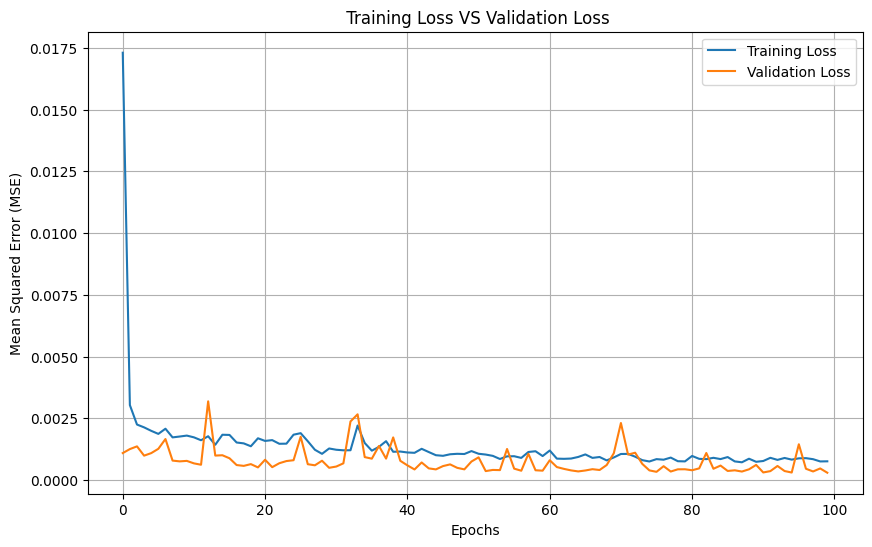

In [ ]:
# Plotting training and validation loss for single step GRU
plt.figure(figsize=(10, 6))
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('GRU Single Step Training Loss VS Validation Loss')
plt.plot(history_gru_single_step.history['loss'], label='GRU Single Step Training Loss')
plt.plot(history_gru_single_step.history['val_loss'], label='GRU Single Step Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

#Prediction using Bi-LSTM


Starting Single Step Bi-LSTM Hyperparameter Tuning...

Training Bi-LSTM with params: units=70, dropout=0.1, lr=0.001, epochs=100, batch_size=32, activation=relu


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Streaming output truncated to the last 5000 lines.
Epoch 41/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0018 - val_loss: 0.0022
Epoch 42/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0020 - val_loss: 0.0015
Epoch 43/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0019 - val_loss: 7.5342e-04
Epoch 44/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0020 - val_loss: 0.0011
Epoch 45/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0021 - val_loss: 7.1220e-04
Epoch 46/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0023 - val_loss: 0.0017
Epoch 47/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0022 - val_loss: 0.0012
Epoch 48/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0019 - val_loss: 0.0016
Epoch 49/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0021 - val_loss: 0.0014
Epoch 50/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0020 - val_loss: 7.5059e-04
Epoch 51/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0020

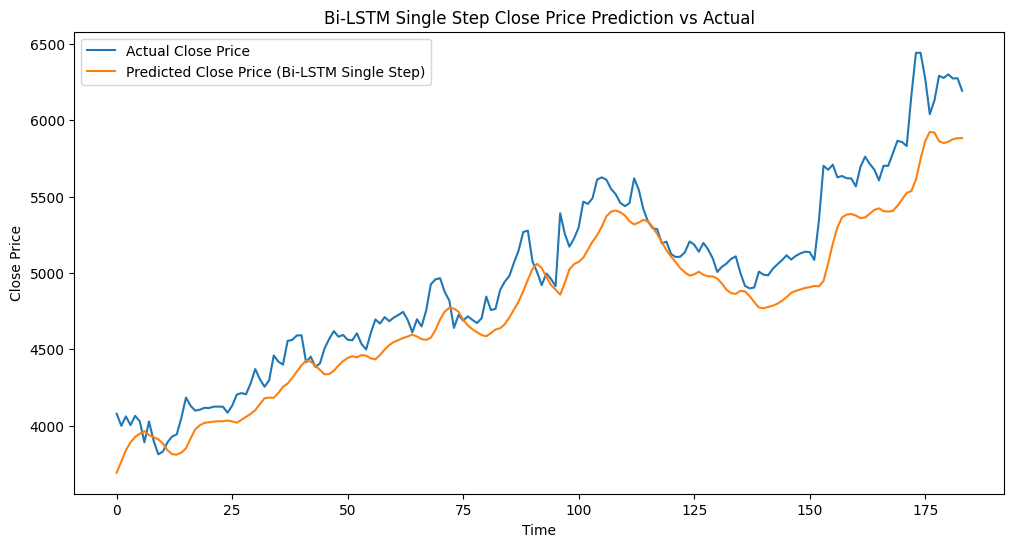


Single Step Bi-LSTM Prediction Results:
   Actual Close Price (Bi-LSTM Single Step)  \
0                                   4079.20   
1                                   4000.10   
2                                   4061.30   
3                                   4004.85   
4                                   4065.20   

   Predicted Close Price (Bi-LSTM Single Step)  
0                                  3692.795898  
1                                  3765.795654  
2                                  3839.740479  
3                                  3891.782471  
4                                  3927.405273  


In [ ]:
# prompt: also create Bi-LSTM to perform same Single step closing price prediction

# --- Single Step Prediction using Bi-LSTM ---

from tensorflow.keras.layers import Bidirectional

# Define the Bi-LSTM model creation function for single step
def build_bi_lstm_single_step(units=50, dropout=0.2, learning_rate=0.001, activation='tanh'):
    model = Sequential()
    # Use Bidirectional wrapper around the LSTM layer
    model.add(Bidirectional(LSTM(units=units, return_sequences=True, activation=activation),
                            input_shape=(X_train.shape[1], X_train.shape[2])))
    model.add(Dropout(dropout))
    model.add(Bidirectional(LSTM(units=units, return_sequences=True, activation=activation),
                            input_shape=(X_train.shape[1], X_train.shape[2])))
    model.add(Dropout(dropout))
    model.add(Bidirectional(LSTM(units=units, return_sequences=False, activation=activation),
                            input_shape=(X_train.shape[1], X_train.shape[2])))
    model.add(Dropout(dropout))
    model.add(Dense(units=1))
    optimizer = Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss='mse')
    return model

# Hyperparameter grid for single step Bi-LSTM (can be similar to LSTM/GRU)
param_grid_bi_lstm_single_step = {
    'units': [70, 100],               #50,
    'dropout': [0.1, 0.2,0.3],            #, 0.3
    'learning_rate': [0.001, 0.0005],
    'epochs': [100], # Reduced epochs for faster grid search   ,100
    'batch_size': [32, 64],
    'activation': ['relu','tanh']            #, 'tanh'
}

best_mse_bi_lstm_single_step = float('inf')
best_params_bi_lstm_single_step = {}
best_model_bi_lstm_single_step = None
history_bi_lstm_single_step = None # To store history of the best model

print("\nStarting Single Step Bi-LSTM Hyperparameter Tuning...")

# Manual Grid Search for Single Step Bi-LSTM
for units in param_grid_bi_lstm_single_step['units']:
    for dropout in param_grid_bi_lstm_single_step['dropout']:
        for learning_rate in param_grid_bi_lstm_single_step['learning_rate']:
            for epochs in param_grid_bi_lstm_single_step['epochs']:
                for batch_size in param_grid_bi_lstm_single_step['batch_size']:
                    for activation in param_grid_bi_lstm_single_step['activation']:
                        print(f"\nTraining Bi-LSTM with params: units={units}, dropout={dropout}, lr={learning_rate}, epochs={epochs}, batch_size={batch_size}, activation={activation}")

                        # Build and train the model
                        model = build_bi_lstm_single_step(units=units, dropout=dropout, learning_rate=learning_rate, activation=activation)

                        history = model.fit(X_train, y_train,
                                            epochs=epochs,
                                            batch_size=batch_size,
                                            validation_data=(X_val, y_val),
                                            verbose=1) # Set to 1 to see progress

                        # Evaluate on validation set
                        val_loss = model.evaluate(X_val, y_val, verbose=0)
                        print(f"Bi-LSTM Validation Loss (MSE): {val_loss}")

                        # Check if this is the best model so far
                        if val_loss < best_mse_bi_lstm_single_step:
                            best_mse_bi_lstm_single_step = val_loss
                            best_params_bi_lstm_single_step = {
                                'units': units,
                                'dropout': dropout,
                                'learning_rate': learning_rate,
                                'epochs': epochs,
                                'batch_size': batch_size,
                                'activation': activation
                            }
                            best_model_bi_lstm_single_step = model
                            history_bi_lstm_single_step = history # Store history of the best model

print("\nSingle Step Bi-LSTM Tuning Complete.")
print("Best Single Step Bi-LSTM Parameters:", best_params_bi_lstm_single_step)
print("Best Single Step Bi-LSTM Validation MSE:", best_mse_bi_lstm_single_step)

# Evaluate the best single step Bi-LSTM model on the test set
y_pred_scaled_bi_lstm_single_step = best_model_bi_lstm_single_step.predict(X_test)
y_test_bi_lstm_single_step = scaler_y.inverse_transform(y_test) # Use the same y_test
y_pred_bi_lstm_single_step = scaler_y.inverse_transform(y_pred_scaled_bi_lstm_single_step)

mse_bi_lstm_single_step = mean_squared_error(y_test_bi_lstm_single_step, y_pred_bi_lstm_single_step)
print(f'\nSingle Step Bi-LSTM Test MSE: {mse_bi_lstm_single_step:.4f}')

# Plotting for single step Bi-LSTM prediction
plt.figure(figsize=(12, 6))
plt.plot(y_test_bi_lstm_single_step, label='Actual Close Price')
plt.plot(y_pred_bi_lstm_single_step, label='Predicted Close Price (Bi-LSTM Single Step)')
plt.title('Bi-LSTM Single Step Close Price Prediction vs Actual')
plt.xlabel('Time')
plt.ylabel('Close Price')
plt.legend()
plt.show()




# Create a DataFrame for single step Bi-LSTM actual vs predicted prices
df_bi_lstm_single_step_results = pd.DataFrame({
    'Actual Close Price (Bi-LSTM Single Step)': y_test_bi_lstm_single_step.flatten(),
    'Predicted Close Price (Bi-LSTM Single Step)': y_pred_bi_lstm_single_step.flatten()
})

print("\nSingle Step Bi-LSTM Prediction Results:")
print(df_bi_lstm_single_step_results.head()) # Display the first few rows





#Model Evaluation

In [ ]:
# Compute evaluation metrics for single step Bi-LSTM prediction

from sklearn.metrics import r2_score

# Compute evaluation metrics for single step prediction

# Mean Absolute Percentage Error (MAPE)
def mean_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    # Avoid division by zero, replace 0 actual values with a small epsilon
    epsilon = np.finfo(np.float64).eps
    return np.mean(np.abs((y_true - y_pred) / np.maximum(epsilon, y_true))) * 100

mape_bi_lstm_single_step = mean_absolute_percentage_error(df_bi_lstm_single_step_results['Actual Close Price (Bi-LSTM Single Step)'],
                                                     df_bi_lstm_single_step_results['Predicted Close Price (Bi-LSTM Single Step)'])

r2_bi_lstm_single_step = r2_score(df_bi_lstm_single_step_results['Actual Close Price (Bi-LSTM Single Step)'],
                             df_bi_lstm_single_step_results['Predicted Close Price (Bi-LSTM Single Step)'])

# MSE is already computed as `mse_bi_lstm_single_step`

rmse_bi_lstm_single_step = np.sqrt(mse_bi_lstm_single_step)

mae_bi_lstm_single_step = np.mean(np.abs(df_bi_lstm_single_step_results['Actual Close Price (Bi-LSTM Single Step)'] -
                                   df_bi_lstm_single_step_results['Predicted Close Price (Bi-LSTM Single Step)']))

print("\nSingle Step Bi-LSTM Evaluation Metrics:")
print(f'MAPE: {mape_bi_lstm_single_step:.2f}%')
print(f'R-squared: {r2_bi_lstm_single_step:.4f}')
print(f'MSE: {mse_bi_lstm_single_step:.4f}')
print(f'RMSE: {rmse_bi_lstm_single_step:.4f}')
print(f'MAE: {mae_bi_lstm_single_step:.4f}')



Single Step Bi-LSTM Evaluation Metrics:
MAPE: 3.91%
R-squared: 0.8400
MSE: 60597.5532
RMSE: 246.1657
MAE: 200.3490


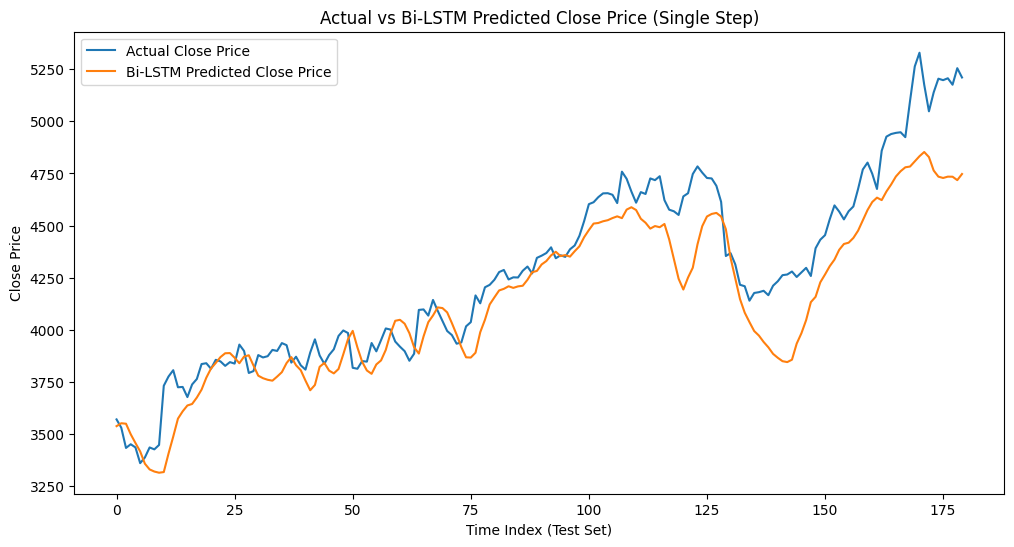

#Interactive plot between Actual and Predicted

In [ ]:
# prompt: plot interactive line graph between actual and predicted value
!pip install plotly
import plotly.express as px

# Interactive plot between Actual and Predicted values (Bi-LSTM)
fig_bi_lstm = px.line(df_bi_lstm_single_step_results, y=['Actual Close Price (Bi-LSTM Single Step)', 'Predicted Close Price (Bi-LSTM Single Step)'],
                      title='Bi-LSTM Single Step Close Price Prediction vs Actual (Interactive)',
                      width=1000, height=400) # Setting figure size
fig_bi_lstm.update_layout(xaxis_title='Time Index', yaxis_title='Close Price')
fig_bi_lstm.show()


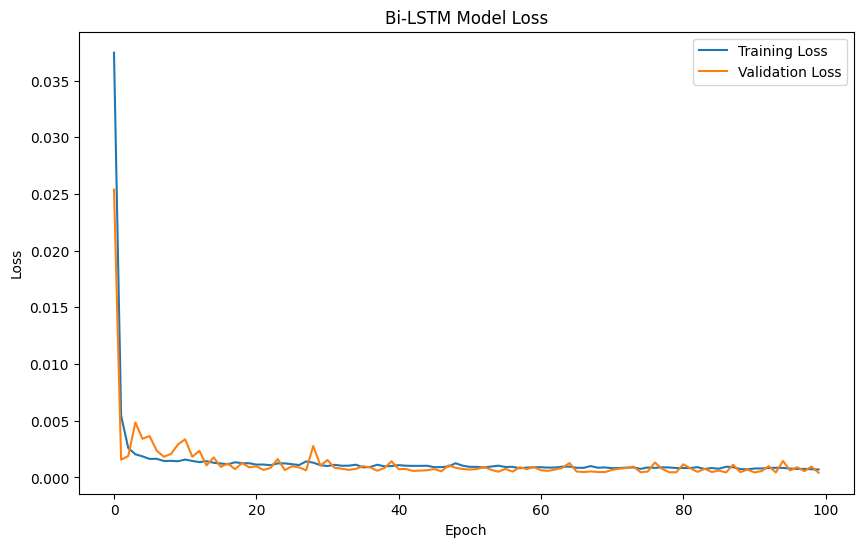

In [ ]:
# prompt: write a code to plot training loss and validation loss of bi lstm

# Plotting training and validation loss for the Bi-LSTM model
plt.figure(figsize=(10, 6))
plt.plot(history_bi_lstm_single_step.history['loss'], label='Training Loss')
plt.plot(history_bi_lstm_single_step.history['val_loss'], label='Validation Loss')
plt.title('Bi-LSTM Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()
